# 03 · E3 — Teorem 1'in birebir testi + β₂ × C ısı haritası
**Sorumlu:** Anıl · **Plan adımları:** A3.2 (Kısım A), A4.1 (Kısım B)

**Kısım A:** $\beta_1=0$, $\beta_2=1/(1+C^2)$, $\alpha_t=\alpha/\sqrt t$, $\alpha<\sqrt{1-\beta_2}$; $f_t(x)=Cx$ ($t \bmod 3=1$), aksi halde $-x$.
İspatın iddiası: **her döngü başında $x_{3t+1}=1$ ve $x$ hep $>0$** ⇒ $R_T/T \ge (2C-4)/3$.

**Kısım B:** Aynı 3 periyotlu problemde $(\beta_2, C)$ ızgarası, $\beta_1 \in \{0, 0.9\}$. Renk = son $\bar x$. Makalede yok — ekibin katkısı.

**Çıktılar:** `results/e3_theorem1/*.csv`, `results/e3_theorem1/heatmap.csv`, `figures/e3_theorem1.*`, `figures/e3_heatmap.*`

## Makaleden sapmalar
| Detay | Bizim seçimimiz | Gerekçe |
|---|---|---|
| Kısım A α | $0.5\sqrt{1-\beta_2}$ | Teoremin koşulu $\alpha<\sqrt{1-\beta_2}$ |
| Kısım A iterasyon | 1M (+2, son döngü tamam) | — |
| Kısım A CSV | Her 3000 adımda bir satır | GitHub dosya boyutu; figür tam çözünürlükten çizilir |
| Kısım B α | $0.1/\sqrt t$ (tüm ızgarada aynı) | Teoremle aynı takvim |
| Kısım B ızgara | $\beta_2$: $10^{-4}$–$0.999$ logit-düzgün 40 nokta; $C$: 2.2–100 log 40 nokta | 0'a ve 1'e yakın β₂ bölgelerini görmek için |
| Kısım B ölçüm | 200k adım, son 6000 adımın $x$ ortalaması | Döngü içi dalgalanmayı ortalamak için |

In [1]:
# --- Kurulum: repo'yu çek, yolları ayarla (00_tests ile aynı) ---
import os, sys, subprocess
REPO = "https://github.com/ybilgici/DeepLearning_Proje.git"
if os.path.exists("/kaggle"):
    ROOT = "/kaggle/working/DeepLearning_Proje"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", REPO, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
else:  # lokal çalıştırma: notebooks/ klasörünün bir üstü repo kökü
    ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import math
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from optim import paper_adam_step, init_state                     # Yiğit — ortak optimizer
from common.synthetic import (simulate, write_csv, online_grad, PeriodicGrad, StochasticGrad,
                              STYLE, style, band, save_fig)

QUICK = os.environ.get("QUICK", "0") == "1"   # True → kısa test koşusu (adım sayıları küçülür)
FIG = os.path.join(ROOT, "figures")
print("torch", torch.__version__, "| QUICK =", QUICK, "| commit:",
      subprocess.run(["git", "-C", ROOT, "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip())

torch 2.15.0+cu132 | QUICK = False | commit: d0b821c


## Kısım A — Teorem 1'in tam örneği (A3.2)

In [2]:
CS = [3.0, 5.0, 10.0]
T_A = 30_001 if QUICK else 1_000_002
rows = []
for o in ("adam", "amsgrad"):
    for C in CS:
        b2 = 1 / (1 + C ** 2)
        rows.append(dict(optimizer=o, C=C, lr=0.5 * math.sqrt(1 - b2), schedule="sqrt", beta1=0.0, beta2=b2, seed=0))
cfgA = pd.DataFrame(rows)
outA = simulate(cfgA, T_A, PeriodicGrad(cfgA["C"].values), x_star=-1.0, log_every=3, track_cycle=(3, 1))
print(f"süre: {outA['seconds']:.0f} s")
keep = (outA["steps"] % 3000 == 0) | (outA["steps"] == outA["steps"][-1])
write_csv("e3_theorem1", cfgA, outA, os.path.join(ROOT, "results/e3_theorem1"), keep=keep)

res = cfgA[["optimizer", "C", "lr", "beta2"]].assign(
    min_x_dongu_basi=outA["min_x_hit"], min_x_tum=outA["min_x_all"],
    R_T_bolu_T=outA["avg_regret_final"], alt_sinir=(2 * cfgA["C"] - 4) / 3)
res["x_3t+1 hep 1?"] = res["min_x_dongu_basi"] >= 1 - 1e-12
res["x hep > 0?"] = res["min_x_tum"] > 0
res

  t=    100,000  (  10.6 s)


  t=    200,000  (  22.7 s)


  t=    300,000  (  35.6 s)


  t=    400,000  (  47.8 s)


  t=    500,000  (  59.0 s)


  t=    600,000  (  71.1 s)


... (2 outputs left out)

  t=    900,000  ( 105.2 s)


  t=  1,000,000  ( 117.7 s)


süre: 119 s


,optimizer,C,lr,beta2,min_x_dongu_basi,min_x_tum,R_T_bolu_T,alt_sinir,x_3t+1 hep 1?,x hep > 0?
0,adam,3.0,0.474342,0.100000,1.000000,0.5,0.667088,0.666667,True,True
1,adam,5.0,0.490290,0.038462,1.000000,0.5,2.000428,2.000000,True,True
2,adam,10.0,0.497519,0.009901,1.000000,0.5,5.333764,5.333333,True,True
3,amsgrad,3.0,0.474342,0.100000,-0.999669,-1.0,0.000608,0.666667,False,False
4,amsgrad,5.0,0.490290,0.038462,-0.999800,-1.0,0.000662,2.000000,False,False
5,amsgrad,10.0,0.497519,0.009901,-0.999900,-1.0,0.000741,5.333333,False,False


kaydedildi: /home/claude/DeepLearning_Proje/figures/e3_theorem1.png / .pdf


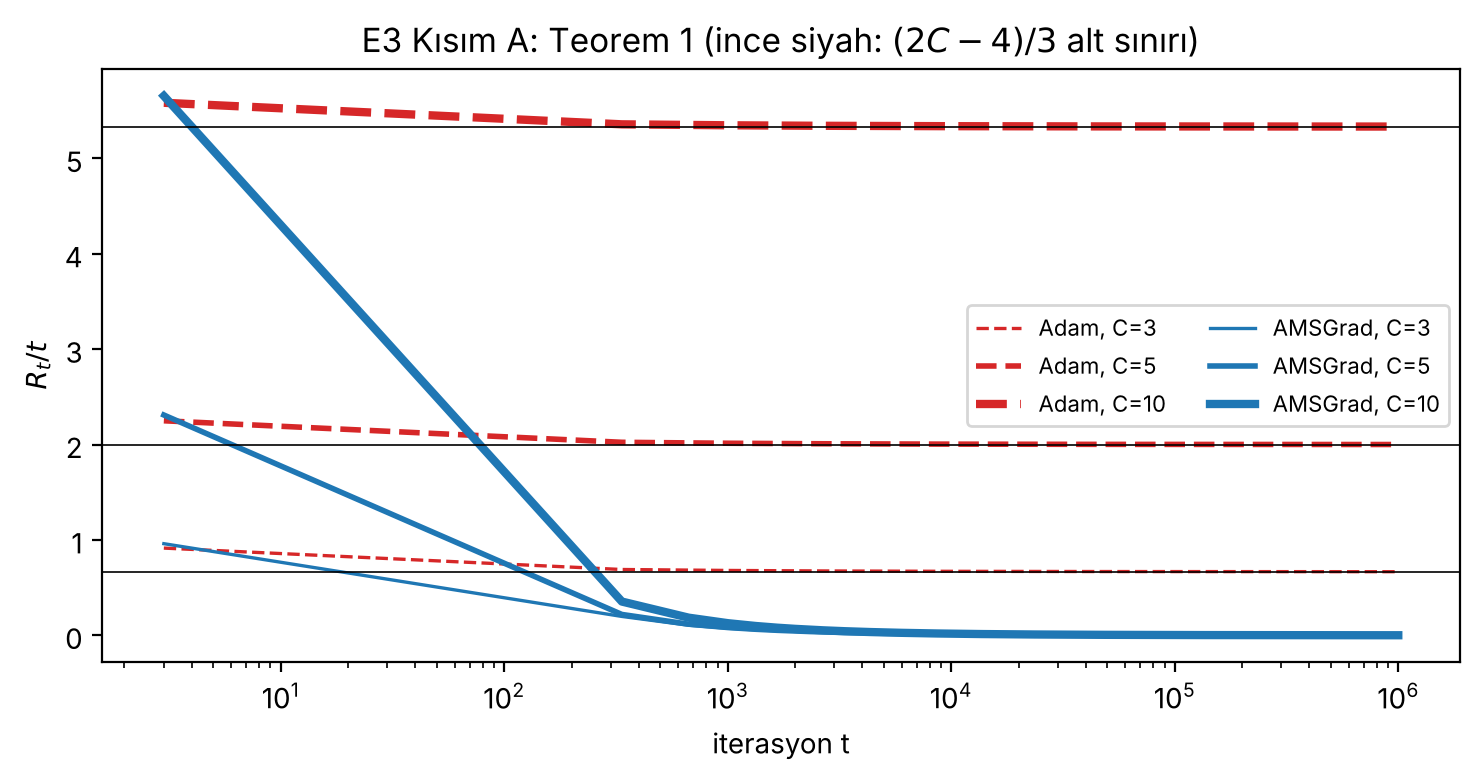

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4))
lw = {3.0: 1.2, 5.0: 2.0, 10.0: 3.0}
step = max(1, len(outA["steps"]) // 3000)
for i, r in cfgA.iterrows():
    ax.plot(outA["steps"][::step], outA["avg_regret"][::step, i],
            **style(r["optimizer"], label=f"{STYLE[r['optimizer']]['label']}, C={r['C']:g}", lw=lw[r["C"]]))
for C in CS:
    ax.axhline((2 * C - 4) / 3, color="k", lw=0.6)
ax.set(xscale="log", xlabel="iterasyon t", ylabel="$R_t/t$", title="E3 Kısım A: Teorem 1 (ince siyah: $(2C-4)/3$ alt sınırı)")
ax.legend(fontsize=8, ncol=2); fig.tight_layout(); save_fig(fig, "e3_theorem1", FIG); plt.show()

### İspatın kalbi: $T_2/T_1$ (iki sağa adımın toplamı / sola adım) her döngüde > 1 mi?
Tam değerlerle hesaplanır, α sadeleşir. İlk döngü ($t=0$) en sıkışık yerdir — makaledeki zincirin bir eşitsizliği burada tek başına yetmez, tam hesap ise geçer.

In [4]:
for C in CS:
    b2 = 1 / (1 + C ** 2); v = 0.0; ratios = []
    for k in range(3000):
        n = 3 * k + 1
        v1 = b2 * v + (1 - b2) * C * C; T1 = C / math.sqrt(n * v1)
        v2 = b2 * v1 + (1 - b2); v3 = b2 * v2 + (1 - b2)
        T2 = 1 / math.sqrt((n + 1) * v2) + 1 / math.sqrt((n + 2) * v3)
        ratios.append(T2 / T1); v = v3
    print(f"C = {C:>4}: ilk döngü T2/T1 = {ratios[0]:.4f} | en küçük = {min(ratios):.4f} | limit ≈ {ratios[-1]:.4f}")

C =  3.0: ilk döngü T2/T1 = 1.0422 | en küçük = 1.0422 | limit ≈ 1.6501
C =  5.0: ilk döngü T2/T1 = 1.0616 | en küçük = 1.0616 | limit ≈ 1.6792
C = 10.0: ilk döngü T2/T1 = 1.0730 | en küçük = 1.0730 | limit ≈ 1.6991


## Kısım B — β₂ × C ısı haritası, β₁ ∈ {0, 0.9} (A4.1)

In [5]:
n = 8 if QUICK else 40
T_B = 20_000 if QUICK else 200_000
TAIL = 600 if QUICK else 6_000
lg = np.linspace(math.log(1e-4 / (1 - 1e-4)), math.log(0.999 / 0.001), n)
B2 = 1 / (1 + np.exp(-lg))                  # logit-düzgün β₂ ızgarası
CG = np.logspace(math.log10(2.2), 2, n)     # C ızgarası
cfgB = pd.DataFrame([dict(optimizer=o, beta1=b1, beta2=b2, C=C, lr=0.1, schedule="sqrt", seed=0)
                     for b1 in (0.0, 0.9) for o in ("adam", "amsgrad") for b2 in B2 for C in CG])
print(f"{len(cfgB)} koşu × {T_B:,} adım")
outB = simulate(cfgB, T_B, PeriodicGrad(cfgB["C"].values), x_star=-1.0, log_every=T_B, tail=TAIL)
print(f"süre: {outB['seconds']:.0f} s")
cfgB["x_tail_mean"] = outB["x_tail"]
cfgB.to_csv(os.path.join(ROOT, "results/e3_theorem1/heatmap.csv"), index=False)

6400 koşu × 200,000 adım


  t=     20,000  (   5.2 s)


  t=     40,000  (  10.2 s)


  t=     60,000  (  14.6 s)


  t=     80,000  (  19.2 s)


  t=    100,000  (  24.0 s)


  t=    120,000  (  29.8 s)


  t=    140,000  (  34.8 s)


  t=    160,000  (  40.2 s)


  t=    180,000  (  45.3 s)


  t=    200,000  (  50.0 s)
süre: 50 s


kaydedildi: /home/claude/DeepLearning_Proje/figures/e3_heatmap.png / .pdf


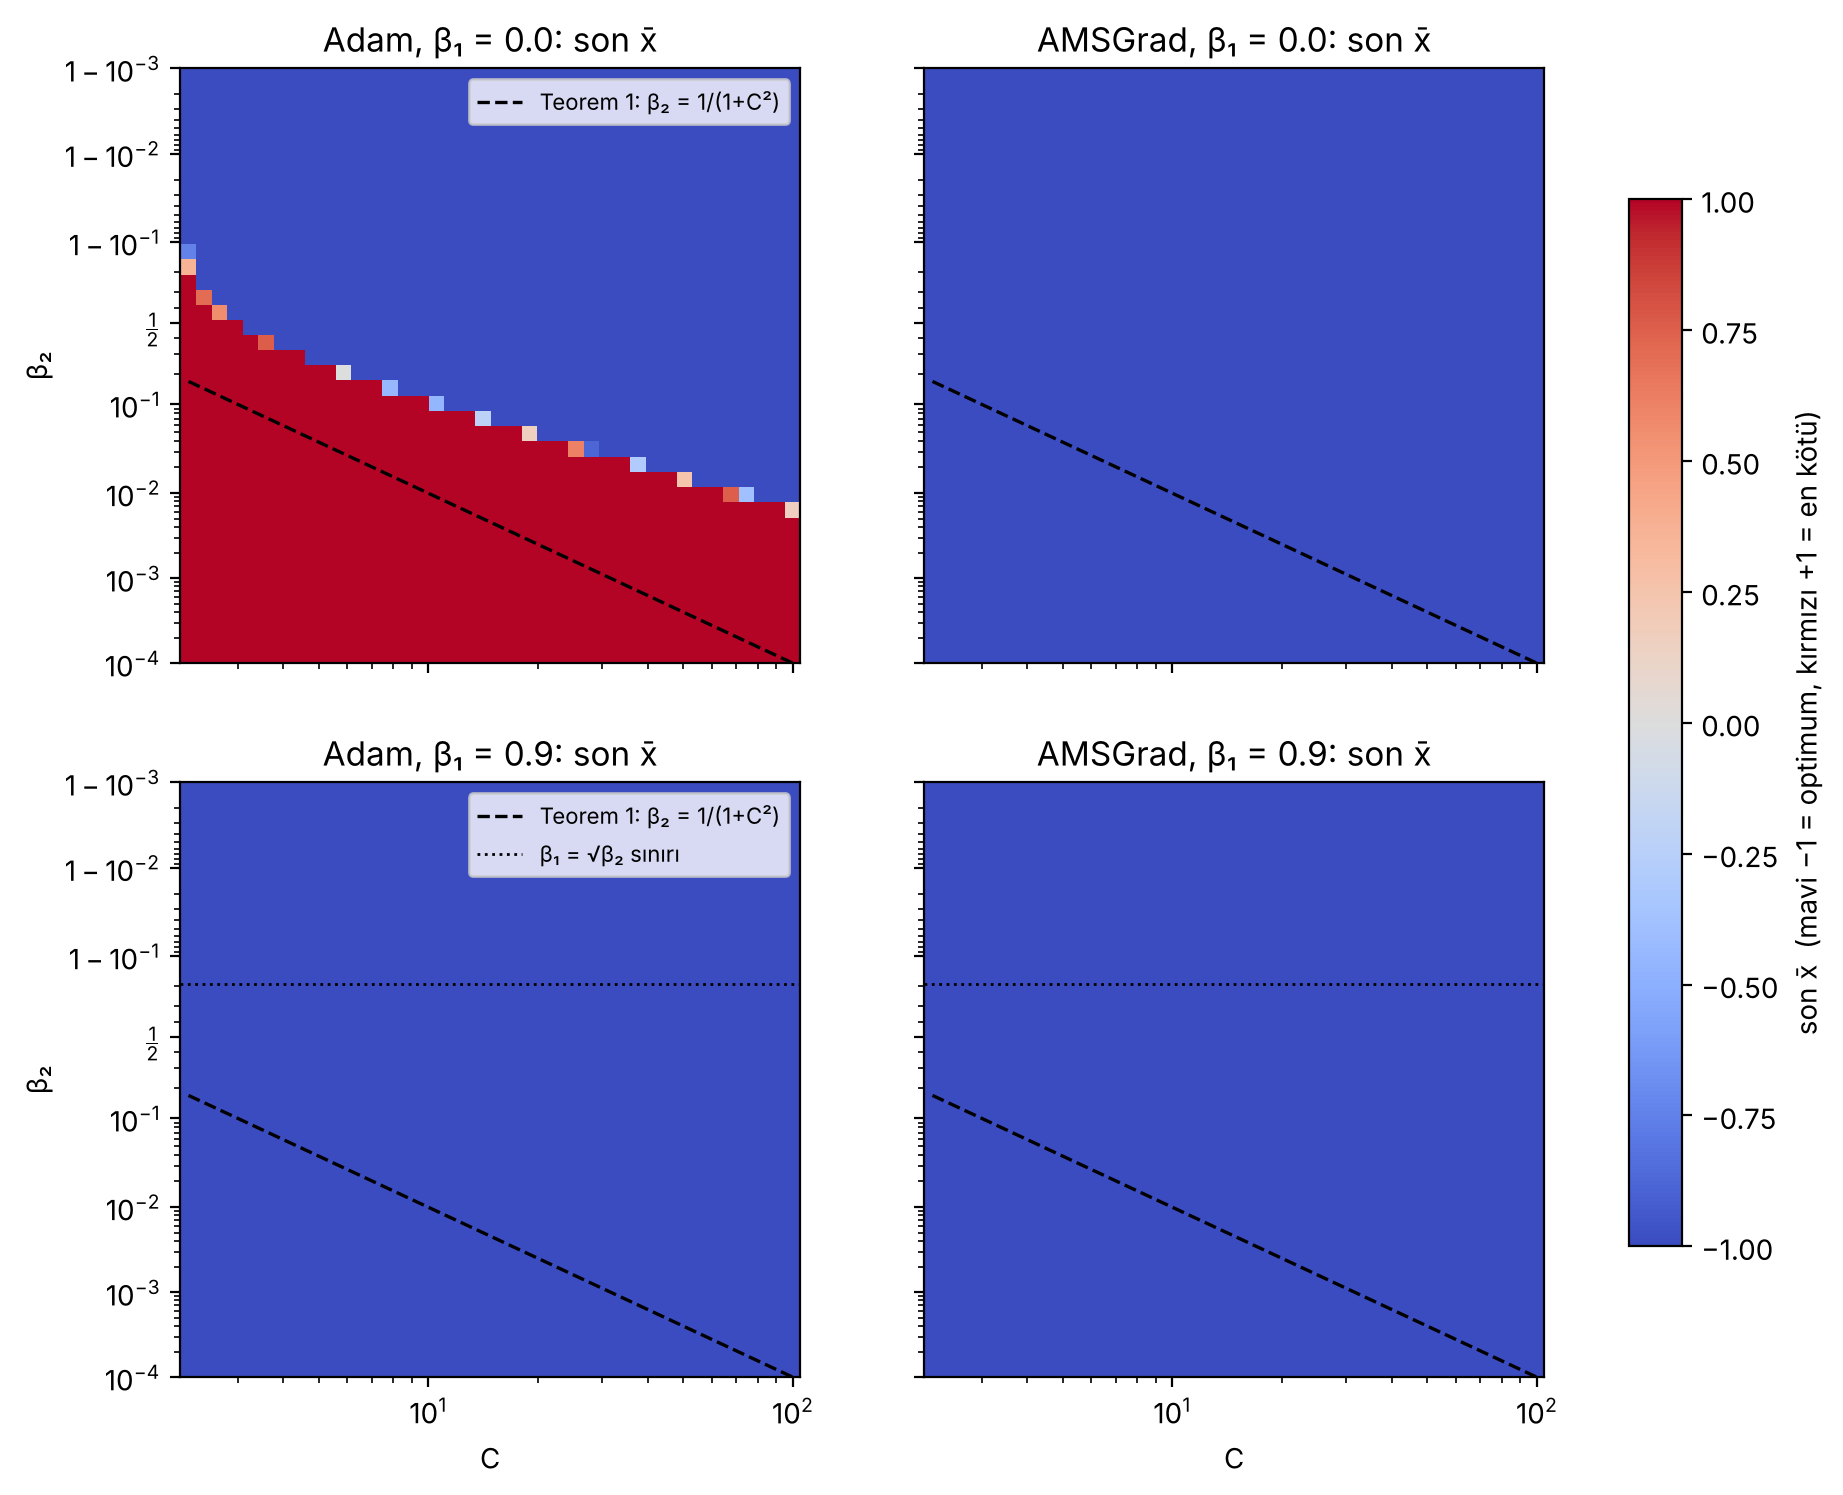

β₁ = 0.0: Adam'ın başarısız olduğu (x̄ > 0) hücre oranı = 41.9%
β₁ = 0.9: Adam'ın başarısız olduğu (x̄ > 0) hücre oranı = 0.0%


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for r_, b1 in enumerate((0.0, 0.9)):
    for c_, o in enumerate(("adam", "amsgrad")):
        ax = axes[r_, c_]
        Z = cfgB[(cfgB.beta1 == b1) & (cfgB.optimizer == o)]["x_tail_mean"].values.reshape(n, n)
        im = ax.pcolormesh(CG, B2, Z, cmap="coolwarm", vmin=-1, vmax=1, shading="nearest")
        ax.plot(CG, 1 / (1 + CG ** 2), "k--", lw=1.2, label="Teorem 1: β₂ = 1/(1+C²)")
        if b1 > 0:
            ax.axhline(b1 ** 2, color="k", ls=":", lw=1, label="β₁ = √β₂ sınırı")
        ax.set(xscale="log", yscale="logit", ylim=(B2[0], B2[-1]), title=f"{STYLE[o]['label']}, β₁ = {b1}: son x̄")
        if r_ == 1: ax.set_xlabel("C")
        if c_ == 0: ax.set_ylabel("β₂")
axes[0, 0].legend(fontsize=8, loc="upper right"); axes[1, 0].legend(fontsize=8, loc="upper right")
cb = fig.colorbar(im, ax=axes, shrink=0.8); cb.set_label("son x̄  (mavi −1 = optimum, kırmızı +1 = en kötü)")
save_fig(fig, "e3_heatmap", FIG); plt.show()

for b1 in (0.0, 0.9):
    sub = cfgB[(cfgB.beta1 == b1) & (cfgB.optimizer == "adam")]
    print(f"β₁ = {b1}: Adam'ın başarısız olduğu (x̄ > 0) hücre oranı = {(sub.x_tail_mean > 0).mean():.1%}")

## Sonuç notları (rapor / slayt 6)
- Kısım A tablosunda Adam için iki sütun da **True** ise ispatın tümevarım iddiası doğrudan gözlendi; $R_T/T$ alt sınırla örtüşüyor.
- Kısım B: Adam'ın başarısız olduğu bölge küçük $\beta_2$'de; Teorem 1'in eğrisi bu bölgenin içinde. Problem sabitken büyük $\beta_2$ ile Adam'ın düzelmesi Zhang ve ark. (NeurIPS 2022) ile uyumlu.
- β₁ = 0.9'da başarısızlık yoksa: momentum bu 3 periyotlu tuzağı kırıyor; Teorem 2 için daha uzun periyotlu bir yapı gerekir.